In [125]:
#import required libraries
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from ipywidgets import interact
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

[[[  0   0   0 255]
  [  0   0   0 255]
  [  0   0   0 255]
  ...
  [  0   0   0 255]
  [  0   0   0 255]
  [  0   0   0 255]]

 [[  0   0   0 255]
  [  0   0   0 255]
  [  0   0   0 255]
  ...
  [  0   0   0 255]
  [  0   0   0 255]
  [  0   0   0 255]]

 [[  0   0   0 255]
  [  0   0   0 255]
  [  0   0   0 255]
  ...
  [  0   0   0 255]
  [  0   0   0 255]
  [  0   0   0 255]]

 ...

 [[  0   0   0 255]
  [  0   0   0 255]
  [  0   0   0 255]
  ...
  [  0   0   0 255]
  [  0   0   0 255]
  [  0   0   0 255]]

 [[  0   0   0 255]
  [  0   0   0 255]
  [  0   0   0 255]
  ...
  [  0   0   0 255]
  [  0   0   0 255]
  [  0   0   0 255]]

 [[  0   0   0 255]
  [  0   0   0 255]
  [  0   0   0 255]
  ...
  [  0   0   0 255]
  [  0   0   0 255]
  [  0   0   0 255]]]
Shape of maze(1).png as numpy array: (210, 210, 4)
Format of image loaded: RGBA


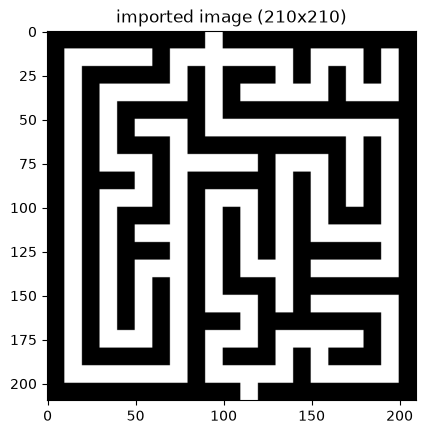

In [35]:
#import maze(1).png
#matplotlib documentation recommends using PIL.image instead of matplotlib.image.imread
#Read an image from a file into a numpy array
img_path = "maze(1).png"
maze_1 = np.array(Image.open(img_path))

#imported image converted to numpy array - display the array
print(maze_1)

#output number of rows, columns and colour channels
print(f"Shape of maze(1).png as numpy array: {maze_1.shape}")

#Confirm format of image
print(f"Format of image loaded: {Image.open(img_path).mode}")

#[255, 255, 255, 255] indicates a white pixel, i.e. pathway
#[0, 0, 0, 255] indicates a black pixel, i.e. wall
#Since image is black and white, we convert it to a binary matrix

#display the imported image
plt.imshow(maze_1)
plt.title(f"imported image ({maze_1.shape[1]}x{maze_1.shape[0]})")
plt.show()

In [7]:
#determine the current height and width of the imported image
height = maze_1.shape[0]
width = maze_1.shape[1]

print(height)
print(width)

#Since the size initial imported image is 210x210 we need to rescale the image


210
210


In [9]:
#step size = ((210-1)-0)/(21-1) = 10.45
#array start at index 0 hence the -1 for the starting index
#Rounds down to the nearest integer


row_i = np.linspace(0, height - 1, 21).astype(int)
col_i = np.linspace(0, width - 1, 21).astype(int)

print(row_i)
print(col_i)

[  0  10  20  31  41  52  62  73  83  94 104 114 125 135 146 156 167 177
 188 198 209]
[  0  10  20  31  41  52  62  73  83  94 104 114 125 135 146 156 167 177
 188 198 209]


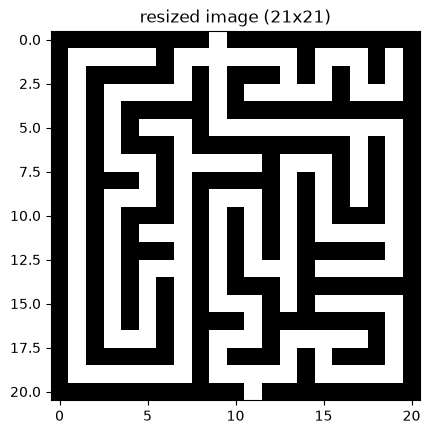

In [12]:
#resize the image to our 21x21 condition

maze_1_21_21 = maze_1[np.ix_(row_i, col_i)]

#display resized image
plt.imshow(maze_1_21_21)
plt.title(f"resized image ({maze_1_21_21.shape[1]}x{maze_1_21_21.shape[0]})")
plt.show()

In [14]:
#Verify height and width of resized image
height_21_21 = maze_1_21_21.shape[0]
width_21_21 = maze_1_21_21.shape[1]

print(height_21_21)
print(width_21_21)

21
21


In [31]:
#convert graph to binary matrix, 1 = wall, 0 = path
#given the RGBA PNG colour array, we can test if any Red/Blue/Green colour is omitted, if any colour is present set to 1 (wall), if no colour is omitted set 0 (pathway)
maze_grid = np.where(maze_1_21_21[:, :, 0] == 0, 1, 0)
print(maze_grid)

[[1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1]
 [1 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 1]
 [1 0 1 1 1 1 1 0 1 0 1 1 1 0 1 0 1 0 1 0 1]
 [1 0 1 0 0 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0 1]
 [1 0 1 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1]
 [1 0 1 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1]
 [1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 1 1 0 1 0 1]
 [1 0 1 0 0 0 1 0 0 0 0 0 1 0 0 0 1 0 1 0 1]
 [1 0 1 1 1 0 1 0 1 1 1 1 1 0 1 0 1 0 1 0 1]
 [1 0 1 0 0 0 1 0 1 0 0 0 1 0 1 0 1 0 1 0 1]
 [1 0 1 0 1 1 1 0 1 0 1 0 1 0 1 0 1 1 1 0 1]
 [1 0 1 0 1 0 0 0 1 0 1 0 1 0 1 0 0 0 0 0 1]
 [1 0 1 0 1 1 1 0 1 0 1 0 1 0 1 1 1 1 1 0 1]
 [1 0 1 0 1 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 1]
 [1 0 1 0 1 0 1 0 1 0 1 1 1 0 1 1 1 1 1 1 1]
 [1 0 1 0 1 0 1 0 1 0 0 0 1 0 1 0 0 0 0 0 1]
 [1 0 1 0 1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 0 1]
 [1 0 1 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 1 0 1]
 [1 0 1 1 1 1 1 0 1 0 1 1 1 0 1 0 1 1 1 0 1]
 [1 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 1]
 [1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1]]
Maze dimensions: (21, 21)


In [42]:
#Find the entrance/starting point of the binary maze, return the element(s)
#Ring fence only the first/last row and column
entrances = []

#Find the elements in the binary maze with value of 0, if 0 then append to entrances array
for row, col in np.argwhere(maze_grid == 0):
    if row in (0, maze_grid.shape[0] - 1) or col in (0, maze_grid.shape[1] - 1):
        entrances.append((int(row), int(col)))

print(f"Binary maze entrance points: {entrances}")

#Assignment allocates the entrance to the top row, so exist subsequently must be last row

starting_point=entrances[0]
print(f"Binary maze starting point: {starting_point}")
exit_point=entrances[1]
print(f"Binary maze exit point: {exit_point}")

Binary maze entrance points: [(0, 9), (20, 11)]
Binary maze starting point: (0, 9)
Binary maze exit point: (20, 11)


In [55]:
#Generate function that will be used to determine if next move is possible
#Possible movement (up/down/left/right) for any given point
#Retain the value of the possible movements next to starting point
movements = [(-1, 0), (1, 0), (0, -1), (0, 1)]

def check_movements(matrix,point):
    n_values =[]
    row,col=point
    
    for r_move, c_move in movements:
        row_get = row + r_move
        col_get = col + c_move
    
        if 0<=row_get<=(height_21_21-1) and 0<=col_get<=width_21_21-1:
            value = int(matrix[row_get, col_get])
            n_values.append(((row_get,col_get),value))
            
    return n_values

check_movements(maze_grid,starting_point)

[((1, 9), 0), ((0, 8), 1), ((0, 10), 1)]

In [57]:
possible_moves=check_movements(maze_grid,starting_point)

In [58]:
print(possible_moves)

[((1, 9), 0), ((0, 8), 1), ((0, 10), 1)]


In [60]:
valid_movements = [points[0] for points in possible_moves if points[1] == 0]
print(valid_movements)

[(1, 9)]


In [65]:
#Determine if any adjcent elements contain a wall and what moves are possible
def valid_movements_check(movements):
    valid_movements = [points[0] for points in movements if points[1] == 0]
    return valid_movements


In [66]:
valid_movements=valid_movements_check(possible_moves)

In [67]:
print(valid_movements) 

[(1, 9)]


In [69]:
#Generate a function to keep track of movements to enable backtracking conditions
def movement_tracker(movement_log, point):
    if point not in movement_log:
        movement_log.append(point)
    return movement_log

In [70]:
movement_log=[]
movement_tracker(movement_log, starting_point)
print(movement_log)

movement_tracker(movement_log, (1, 9))
print(movement_log)

movement_tracker(movement_log, (0, 9))
print(movement_log)

[(0, 9)]
[(0, 9), (1, 9)]
[(0, 9), (1, 9)]


In [73]:
#Identify unexplored moves available for backtracking conditions
def unexplored_movements(valid_moves, movement_log):
    unexplored = [point for point in valid_moves if point not in movement_log]
    return unexplored

In [77]:
unexplored = unexplored_movements(valid_movements, movement_log)

if not unexplored:
    print("No possible movements available")
else:
    print(f"Unexplored movements: {unexplored}")

Unexplored movements: [(1, 9)]


In [132]:
#Choose first available movement if possible and not explored
movement_log = [starting_point]
current_path = [starting_point]
def next_movement(unexplored, current_path):

    
    if unexplored:
        next_point = unexplored[0]
        current_path.append(next_point)
        return next_point

    #If no unexplored movements exist, backtrack
    else:
        print("No next movements available - backtrack one step")

        #Go want step back and remove the current position from the stack
        current_path.pop()

        #Return to the previous position
        if current_path:
            return current_path[-1]

        #No movements remaining to explore
        return None

In [84]:
#Initialize tracking
movement_log = [starting_point]
current_path = [starting_point]

#Determine available movements
possible_moves = check_movements(maze_grid, starting_point)
valid_moves = valid_movements_check(possible_moves)
unexplored = unexplored_movements(valid_moves, movement_log)

#Select the next position
next_point = next_movement(unexplored, current_path)

#Record the visited position
if next_point is not None:
    movement_tracker(movement_log, next_point)

print("Current position:", next_point)
print("Movement log:", movement_log)
print("current path:", current_path)

Current position: (1, 9)
Movement log: [(0, 9), (1, 9)]
current path: [(0, 9), (1, 9)]


In [89]:
#Initialize tracking
movement_log = [starting_point]
current_path = [starting_point]

#Determine available movements
possible_moves = check_movements(maze_grid, starting_point)
valid_moves = valid_movements_check(possible_moves)
unexplored = unexplored_movements(valid_moves, movement_log)

#Select the next position
next_point = next_movement(unexplored, current_path)

#Record the visited position
if next_point is not None:
    movement_tracker(movement_log, next_point)

print("Current position:", next_point)
print("Movement log:", movement_log)
print("current path:", current_path)

Current position: (1, 9)
Movement log: [(0, 9), (1, 9)]
current path: [(0, 9), (1, 9)]


In [90]:
current_path = [(0, 9)]
unexplored = [(1, 9)]

next_point = next_movement(unexplored, current_path)

print("Next point:", next_point)
print("current path:", current_path)

Next point: (1, 9)
current path: [(0, 9), (1, 9)]


In [91]:
current_path = [(0, 9), (1, 9), (2, 9)]
unexplored = []

next_point = next_movement(unexplored, current_path)

print("Next point:", next_point)
print("current path:", current_path)

No possible movements available
Next point: (1, 9)
current path: [(0, 9), (1, 9)]


In [92]:
current_path = [(0, 9)]
unexplored = []

next_point = next_movement(unexplored, current_path)

print("Next point:", next_point)
print("current path:", current_path)

No possible movements available
Next point: None
current path: []


In [93]:
#Initialize a new run
movement_log = [starting_point]
current_path = [starting_point]

#Step1 Find possible movements
possible_moves = check_movements(maze_grid, starting_point)

#Step2 find valid movements
valid_moves = valid_movements_check(possible_moves)

#Step3 Remove explored movements
unexplored = unexplored_movements(valid_moves, movement_log)

#Step4 Select next point point to visit
next_point = next_movement(unexplored, current_path)

#Step5 log movement
if next_point is not None:
    movement_tracker(movement_log, next_point)

print("Next position:", next_point)
print("Current path:", current_path)
print("Movement log:", movement_log)

Next position: (1, 9)
Current path: [(0, 9), (1, 9)]
Movement log: [(0, 9), (1, 9)]


In [111]:
#Start new run with backtracking
movement_log = [starting_point]
movement_all_log = [starting_point]
current_path = [starting_point]
current_point = starting_point
moves=0

while current_point != exit_point:

    #Step1 Find possible movements
    possible_moves = check_movements(maze_grid, current_point)

    #Step2 Find valid movements
    valid_moves = valid_movements_check(possible_moves)

    #Step3 Remove explored movements
    unexplored = unexplored_movements(valid_moves, movement_log)

    #Step4 Select next movement
    previous_path_length = len(current_path)
    next_point = next_movement(unexplored, current_path)
    if len(current_path) < previous_path_length:
        print(f"Backtracking to {next_point}")
        current_point = next_point


    #Stop if no movements remain
    if next_point is None:
        break

    
    #Step5 Log movement
    movement_all_log.append(next_point)
    movement_tracker(movement_log, next_point)

    if current_point != next_point:
        print(f"current point: {current_point} and move to next point {next_point}")
    #Update current point
    current_point = next_point
    moves=moves+1

print("Current path:", current_path)
print("Unique movement log:", movement_log)
print("Overall movement log:", movement_all_log)

final_path_length = len(current_path)
if current_point == exit_point:
    print(f"Successfully reached the exit at {exit_point} with a path length of {final_path_length} and total movements of {moves}")
else:
    print("No solution found")

current point: (0, 9) and move to next point (1, 9)
current point: (1, 9) and move to next point (2, 9)
current point: (2, 9) and move to next point (3, 9)
current point: (3, 9) and move to next point (4, 9)
current point: (4, 9) and move to next point (5, 9)
current point: (5, 9) and move to next point (5, 10)
current point: (5, 10) and move to next point (5, 11)
current point: (5, 11) and move to next point (5, 12)
current point: (5, 12) and move to next point (5, 13)
current point: (5, 13) and move to next point (5, 14)
current point: (5, 14) and move to next point (5, 15)
current point: (5, 15) and move to next point (5, 16)
current point: (5, 16) and move to next point (5, 17)
current point: (5, 17) and move to next point (6, 17)
current point: (6, 17) and move to next point (7, 17)
current point: (7, 17) and move to next point (8, 17)
current point: (8, 17) and move to next point (9, 17)
No next movements available - backtrack one step
Backtracking to (8, 17)
No next movements av

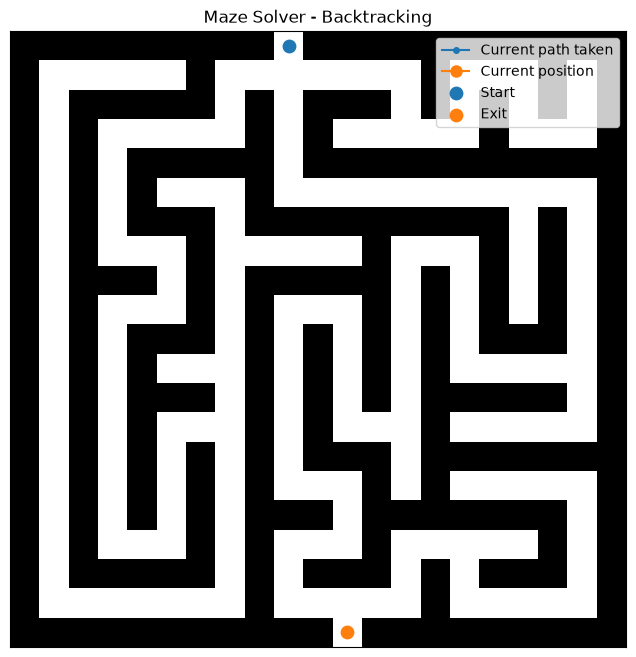

In [114]:
#Generate gif of movements
history = np.array(movement_all_log)
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(maze_grid, cmap='gray_r')
ax.set_title("Maze Solver - Backtracking")
ax.set_xticks([])
ax.set_yticks([])
trail, = ax.plot([], [], marker='o', linestyle='-', markersize=4, label='Current path taken')
current_dot, = ax.plot([], [], marker='o', markersize=8, label='Current position')
ax.scatter(starting_point[1], starting_point[0], s=80, label='Start')
ax.scatter(exit_point[1], exit_point[0], s=80, label='Exit')
ax.legend()

In [115]:
#Generate function to show movements for gif
def update(frame):
    path_so_far = history[:frame + 1]
    x_vals = path_so_far[:, 1]
    y_vals = path_so_far[:, 0]
    trail.set_data(x_vals, y_vals)
    current_dot.set_data([x_vals[-1]], [y_vals[-1]])

    ax.set_title(f"Maze Solver - Backtracking movement {frame}")
    return trail, current_dot

In [120]:
gif_maze = FuncAnimation(
    fig,
    update,
    frames=len(history),
    interval=300,   
    blit=True,
    repeat=False
)

gif_maze.save("maze_backtracking.gif", writer=PillowWriter(fps=3))
plt.show()

In [135]:
#Combine into one function for backtracking
def backtracking(matrix,starting_point,exit_point):
    movement_log = [starting_point]
    movement_all_log = [starting_point]
    current_path = [starting_point]
    current_point = starting_point
    moves=0
    success_count = 0
    
    while current_point != exit_point:
    
        #Step1 Find possible movements
        possible_moves = check_movements(matrix, current_point)
    
        #Step2 Find valid movements
        valid_moves = valid_movements_check(possible_moves)
    
        #Step3 Remove explored movements
        unexplored = unexplored_movements(valid_moves, movement_log)
    
        #Step4 Select next movement
        previous_path_length = len(current_path)
        next_point = next_movement(unexplored, current_path)
        if len(current_path) < previous_path_length:
            print(f"Backtracking to {next_point}")
            current_point = next_point
    
    
        #Stop if no movements remain
        if next_point is None:
            break
    
        
        #Step5 Log movement
        movement_all_log.append(next_point)
        movement_tracker(movement_log, next_point)
    
        if current_point != next_point:
            print(f"current point: {current_point} and move to next point {next_point}")
        #Update current point
        current_point = next_point
        moves=moves+1

        if current_point == exit_point:
            success_count += 1
            
    return {
    "moves": moves,
    "movement_log": movement_log,
    "movement_all_log": movement_all_log,
    "current_path": current_path,
    "path_length": len(current_path),
    "success_count": success_count,
    }

backtracking_result = backtracking(
    maze_grid,
    starting_point,
    exit_point
)

print("Total movements:", backtracking_result["moves"])
print("Final path length:", backtracking_result["path_length"])
print("Unique visited positions:", len(backtracking_result["movement_log"]))
print("Animation positions:", len(backtracking_result["movement_all_log"]))
print("Succesfull exists:", backtracking_result["success_count"])

current point: (0, 9) and move to next point (1, 9)
current point: (1, 9) and move to next point (2, 9)
current point: (2, 9) and move to next point (3, 9)
current point: (3, 9) and move to next point (4, 9)
current point: (4, 9) and move to next point (5, 9)
current point: (5, 9) and move to next point (5, 10)
current point: (5, 10) and move to next point (5, 11)
current point: (5, 11) and move to next point (5, 12)
current point: (5, 12) and move to next point (5, 13)
current point: (5, 13) and move to next point (5, 14)
current point: (5, 14) and move to next point (5, 15)
current point: (5, 15) and move to next point (5, 16)
current point: (5, 16) and move to next point (5, 17)
current point: (5, 17) and move to next point (6, 17)
current point: (6, 17) and move to next point (7, 17)
current point: (7, 17) and move to next point (8, 17)
current point: (8, 17) and move to next point (9, 17)
No next movements available - backtrack one step
Backtracking to (8, 17)
No next movements av

In [136]:
def generate_maze_gif(matrix, movement_all_log, algorithm, starting_point, exit_point, fps=4):

    history = np.array(movement_all_log)

    #create/Overwrite file
    gif_filename = f"maze_{algorithm.lower().replace(' ', '_')}.gif"

    #Generate maze
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(matrix, cmap="gray_r")

    #Create movement points
    trail, = ax.plot([], [], "b.-", linewidth=2,markersize=4, label="Movement history")

    current_dot, = ax.plot([], [], "ro", markersize=8,label="Current position")

    # Mark entrance and exit
    ax.plot(starting_point[1], starting_point[0],"go", markersize=9, label="Entrance")

    ax.plot(exit_point[1], exit_point[0],"mo", markersize=9, label="Exit")

    ax.set_xticks([])
    ax.set_yticks([])
    ax.legend()

    #Plot movement point for each frame
    def update(frame):
        path_so_far = history[:frame + 1]

        x = path_so_far[:, 1]  # Columns
        y = path_so_far[:, 0]  # Rows

        trail.set_data(x, y)
        current_dot.set_data([x[-1]], [y[-1]])

        ax.set_title(f"{algorithm} - Movement {frame}")

        return trail, current_dot

    #Generate gif for each frame
    gif = FuncAnimation(
        fig,
        update,
        frames=len(history),
        interval=1000 / fps,
        blit=False,
        repeat=False
    )

    
    gif.save(gif_filename, writer=PillowWriter(fps=fps))
    plt.close(fig)

    return gif_filename

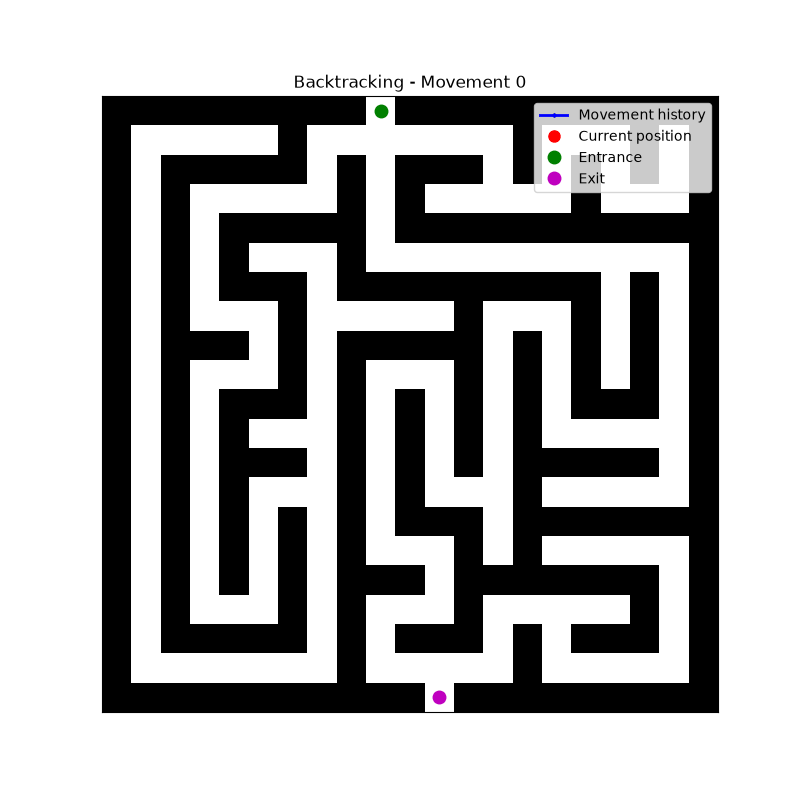

In [137]:
gif_file = generate_maze_gif(
    maze_grid,
    backtracking_result["movement_all_log"],
    "Backtracking",
    starting_point,
    exit_point
)


display(Image(filename=gif_file))

In [138]:
#Las Vegas approach with random direction selection
def random_movement(valid_moves):

    #Check if any movements are available
    if not valid_moves:
        return None

    #Randomly select a valid movement
    random_index = np.random.randint(0, len(valid_moves))
    next_move = valid_moves[random_index]

    return next_move

In [144]:
# Initialize Las Vegas test
movement_log = [starting_point]
movement_all_log = [starting_point]
current_point = starting_point
moves = 0

# Test 10 random movements
for step in range(10):

    # Step 1: Find possible movements
    possible_moves = check_movements(maze_grid, current_point)

    # Step 2: Find valid movements
    valid_moves = valid_movements_check(possible_moves)

    # Step 3: Randomly select next movement
    next_point = random_movement(valid_moves)

    # Stop if no valid movements exist
    if next_point is None:
        break

    # Step 4: Log movement
    movement_all_log.append(next_point)
    movement_tracker(movement_log, next_point)

    print(f"Movement {step + 1}: {current_point} -> {next_point}")

    # Step 5: Update current position and movement count
    current_point = next_point
    moves += 1

    # Stop if exit is reached
    if current_point == exit_point:
        break

print("Total movements:", moves)
print("Unique visited positions:", len(movement_log))
print("All movements:", movement_all_log)
    

Movement 1: (0, 9) -> (1, 9)
Movement 2: (1, 9) -> (1, 8)
Movement 3: (1, 8) -> (1, 9)
Movement 4: (1, 9) -> (0, 9)
Movement 5: (0, 9) -> (1, 9)
Movement 6: (1, 9) -> (0, 9)
Movement 7: (0, 9) -> (1, 9)
Movement 8: (1, 9) -> (2, 9)
Movement 9: (2, 9) -> (1, 9)
Movement 10: (1, 9) -> (1, 10)
Total movements: 10
Unique visited positions: 5
All movements: [(0, 9), (1, 9), (1, 8), (1, 9), (0, 9), (1, 9), (0, 9), (1, 9), (2, 9), (1, 9), (1, 10)]


In [146]:
def las_vegas(matrix, starting_point, exit_point):

    # Initialize a new run
    movement_log = [starting_point]
    movement_all_log = [starting_point]
    current_point = starting_point
    moves = 0
    success_count = 0

    # Continue until exit found or 200 movements completed
    while current_point != exit_point and moves < 200:

        # Step 1: Find possible movements
        possible_moves = check_movements(matrix, current_point)

        # Step 2: Find valid movements
        valid_moves = valid_movements_check(possible_moves)

        # Step 3: Randomly select next movement
        next_point = random_movement(valid_moves)

        # Stop if no valid movements exist
        if next_point is None:
            break

        # Step 4: Log movement
        movement_all_log.append(next_point)
        movement_tracker(movement_log, next_point)

        # Step 5: Update current position
        current_point = next_point
        moves += 1

    # Record successful attempts
    if current_point == exit_point:
        success_count += 1

    return {
        "success_count": success_count,
        "moves": moves,
        "movement_log": movement_log,
        "movement_all_log": movement_all_log
    }

In [174]:
total_runs = 1
total_successes = 0

for run in range(total_runs):

    result = las_vegas(maze_grid, starting_point, exit_point)
    total_successes += result["success_count"]

success_rate = (total_successes / total_runs) * 100

print("Total runs:", total_runs)
print("Successful runs:", total_successes)
print(f"Success rate: {success_rate:.2f}%")
print("Movement log:", result["movement_all_log"])

Total runs: 1
Successful runs: 0
Success rate: 0.00%
Movement log: [(0, 9), (1, 9), (1, 10), (1, 9), (1, 8), (1, 9), (1, 10), (1, 11), (1, 10), (1, 9), (1, 10), (1, 11), (1, 10), (1, 9), (0, 9), (1, 9), (1, 10), (1, 11), (1, 12), (1, 13), (1, 12), (1, 11), (1, 12), (1, 11), (1, 12), (1, 13), (1, 12), (1, 13), (1, 12), (1, 11), (1, 12), (1, 11), (1, 12), (1, 13), (2, 13), (1, 13), (2, 13), (3, 13), (3, 12), (3, 13), (2, 13), (3, 13), (3, 12), (3, 11), (3, 12), (3, 13), (3, 14), (3, 13), (2, 13), (1, 13), (2, 13), (1, 13), (2, 13), (3, 13), (3, 12), (3, 11), (3, 12), (3, 13), (3, 14), (3, 15), (2, 15), (1, 15), (2, 15), (1, 15), (1, 16), (1, 15), (2, 15), (1, 15), (2, 15), (3, 15), (3, 14), (3, 13), (2, 13), (3, 13), (2, 13), (1, 13), (2, 13), (1, 13), (2, 13), (1, 13), (2, 13), (1, 13), (2, 13), (1, 13), (2, 13), (3, 13), (2, 13), (1, 13), (1, 12), (1, 11), (1, 10), (1, 9), (1, 8), (1, 9), (0, 9), (1, 9), (2, 9), (1, 9), (2, 9), (1, 9), (1, 8), (1, 7), (1, 8), (1, 7), (2, 7), (1, 7), (2

In [169]:
#ask user what approach they want to take
#Use drop down list to avoid the user selecting an option that is not in scope - we will ipywidgets libraries to force this
def method(user_method=["Backtracking", "Las Vegas"]):
    global method
    method = user_method
    print(f"Active Method: {method}")

interact(method);

interactive(children=(Dropdown(description='user_method', options=('Backtracking', 'Las Vegas'), value='Backtr…

In [185]:
#confirm that the method/approach is captured correctly when a new selection is made
if method == "Backtracking":
    total_runs = 1
    result = backtracking(maze_grid, starting_point, exit_point)

elif method == "Las Vegas":
    result = las_vegas(maze_grid, starting_point, exit_point)

print("Successful attempts:", result["success_count"])
print("Total movements:", result["moves"])
print("Unique positions:", len(result["movement_log"]))
print("Total runs:", total_runs)

Successful attempts: 0
Total movements: 200
Unique positions: 38
Total runs: 1


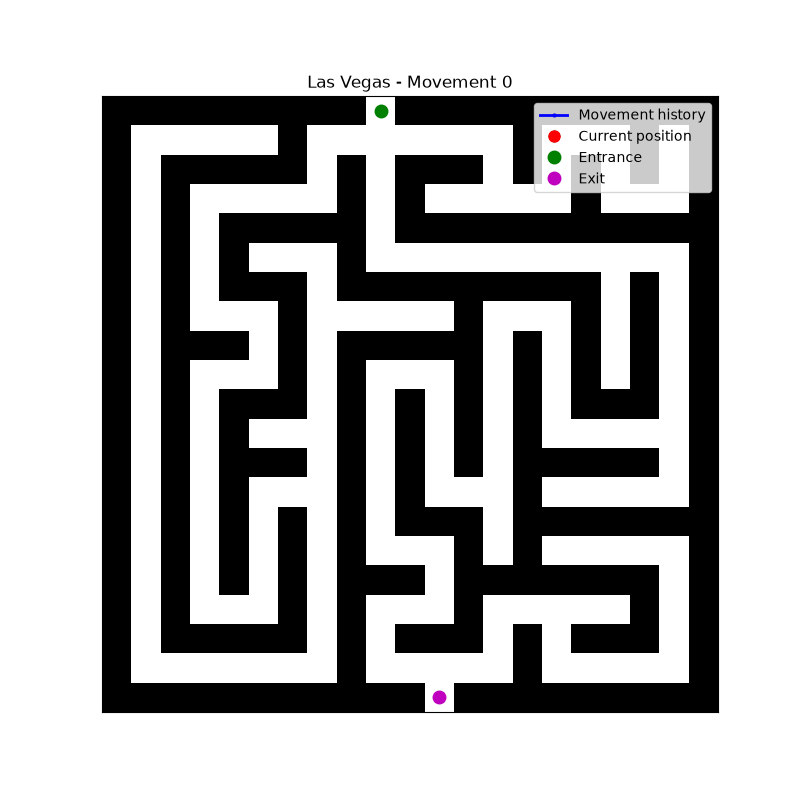

In [186]:
gif_file = generate_maze_gif(
    maze_grid,
    result["movement_all_log"],
    method,
    starting_point,
    exit_point
)


display(Image(filename=gif_file))